# 07. Turn a photograph into a recoverable observation

Build a capture flow that respects permission, preserves the original, and prepares a separate upload image.

**55 minutes including practice · Branch**

This is a **Python 3 notebook**. It contains the complete lesson, embedded vector illustrations, React Native examples for reading, and executable Python models. Python does not run React Native. Run the `.tsx` exercise in Expo using the workbook instructions. No cloud credentials or live services are needed for the notebook.

Run the cells from top to bottom. Change a control, make a prediction, then explain the result. If widgets are unavailable, edit a model's default arguments and rerun its cell.

If you have the complete course folder, [open the interactive guide](../index.html#lesson-07) or [read the exercise instructions](../exercises/README.md). These companion links are absent in a notebooks-only or single-lesson download; the notebook itself still runs independently.


## What you will be able to do

- You can explain why permission and camera readiness are separate states.
- You can distinguish a temporary capture URI, a retained original, and a prepared derivative.
- You can give a person a useful next action after cancellation, denial, or image-processing failure.

## Before you begin

You can use state, refs, async functions, and an authenticated API boundary.

You have completed lessons 01–06.


In [1]:
from IPython.display import display, HTML, SVG
import json
import os
import inspect

# Widgets are optional. Without them, edit parameters and rerun the model cell.
try:
    if os.environ.get('PLANTOPEDIA_NO_WIDGETS') == '1':
        raise ImportError('Widget-free verification mode')
    import ipywidgets as widgets
except ImportError:
    widgets = None

def explore(function, **controls):
    if widgets is not None:
        display(widgets.interactive(function, **controls))
    else:
        print('Optional controls are unavailable. Edit the explorer function defaults and rerun this model cell.')
        defaults = {name: parameter.default for name, parameter in inspect.signature(function).parameters.items()}
        print('Using function defaults:', defaults)
        function()

print('Python teaching model ready. React Native TSX runs separately in Expo.')


Python teaching model ready. React Native TSX runs separately in Expo.


A camera screen has more states than an open lens and a shutter button. The operating system can deny permission. The camera can be mounted but not ready. A person can leave the screen while image preparation is still working. A photograph can exist in a temporary location that will not survive a later cleanup. Each state changes what the interface should promise.

Plantopedia treats the photograph as evidence for an observation of one specimen. The app first retains an original and records a draft. It then creates a separate prepared image for upload. This order gives a failed preparation step somewhere to return to. You will trace that order and build a smaller capture component before attempting the whole workflow.


## Ask when the action needs the camera

The permission result initially may still be loading. Once it arrives, the app can distinguish granted access from a denial. If the system allows another request, explain why the camera helps and offer a clear button. If it no longer allows another request, repeating the same request is frustrating. Offer settings or another input path instead. A cancelled gallery picker is an ordinary decision to return, not an upload error.

The teaching component below covers permission and a first capture. It deliberately receives an onCaptured callback instead of inventing a storage service. The caller owns the next step. The example also waits for onCameraReady, uses a ref to reject a second simultaneous capture, and renders a visible error if the capture fails. These are separate responsibilities: state changes the display, while a ref can guard an operation immediately between renders.

Use this component inside an Expo screen in your course copy. It is not a replacement for Plantopedia's fuller CaptureScreen, which handles focus changes, drafts, gallery selection, preparation, saving, and navigation. On the web, camera behavior also depends on browser support and a secure origin. The HTML lab models decisions; it does not open your physical camera.


**Teaching example: CameraLesson.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { useRef, useState } from 'react';
import { Button, Linking, Text, View } from 'react-native';
import { CameraView, useCameraPermissions } from 'expo-camera';

export function CameraLesson({ onCaptured }: {
  onCaptured: (uri: string) => Promise<void>;
}) {
  const [permission, requestPermission] = useCameraPermissions();
  const camera = useRef<CameraView>(null);
  const inFlight = useRef(false);
  const [ready, setReady] = useState(false);
  const [busy, setBusy] = useState(false);
  const [error, setError] = useState('');
  async function capture() {
    if (!ready || inFlight.current || !camera.current) return;
    inFlight.current = true;
    setBusy(true);
    setError('');
    try {
      const image = await camera.current.takePictureAsync({ exif: false });
      if (!image) throw new Error('No photo was returned.');
      await onCaptured(image.uri);
    } catch {
      setError('The photo could not be captured. Please try again.');
    } finally {
      inFlight.current = false;
      setBusy(false);
    }
  }
  if (!permission) return <Text>Checking camera permission…</Text>;
  if (!permission.granted) {
    return <View style={{ gap: 12 }}>
      <Text>Use the camera to photograph a plant observation.</Text>
      <Button
        title={permission.canAskAgain ? 'Allow camera' : 'Open settings'}
        onPress={() => {
          void (permission.canAskAgain ? requestPermission() : Linking.openSettings());
        }} />
    </View>;
  }
  return <View style={{ gap: 12 }}>
    <CameraView ref={camera} style={{ height: 320 }}
      onCameraReady={() => setReady(true)} />
    <Button title={busy ? 'Preparing…' : 'Take photo'}
      disabled={!ready || busy} onPress={() => void capture()} />
    {error ? <Text accessibilityLiveRegion="polite">{error}</Text> : null}
  </View>;
}
```


## Preserve the original before doing work that can fail

A URI names a resource; it does not mean that resource is permanent or uploaded. The URI returned by capture may point into temporary app storage. Plantopedia's native local.retain copies the original into an owner-specific directory under the app's document storage and awaits the copy before returning. It then saves the draft before preparing the image. If preparation fails, the retained original and draft are still available for a retry.

The following provider-dependent excerpt illustrates the first part of that sequence using the actual Draft fields. Each observation and photo gets its own stable identifier. The capturedAt value records when the observation was captured rather than when the network eventually accepts it. The example returns a draft with derivative set to null because preparation is a later step. It is not yet ready for upload. The current shared draft schema also requires mode; this plant example sets it to plant.

Durable evidence and immediate visual feedback serve different purposes. Showing a preview tells the person which photograph they chose. Saving the draft tells the app how to recover it after a process restart. An image on screen proves neither successful storage nor a completed API operation.


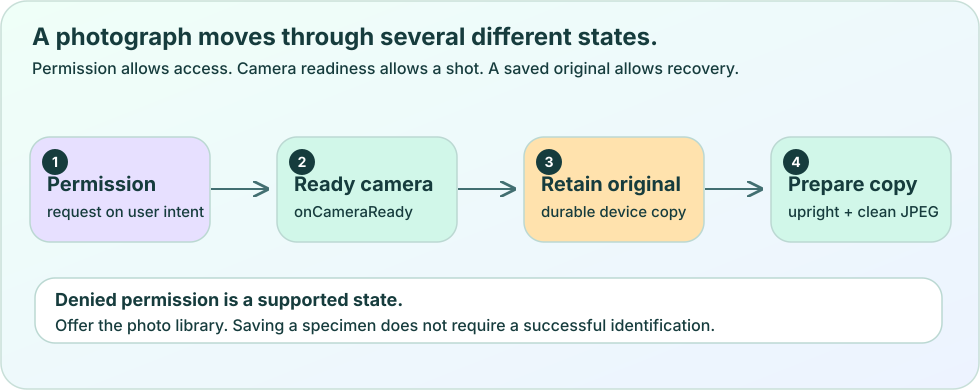

In [2]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Camera permission, readiness, and retention</title><desc id="desc">A permission request is followed by a ready camera, retention of the original, and preparation of a separate upload derivative. Denied permission can lead to choosing a library photo.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">A photograph moves through several different states.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Permission allows access. Camera readiness allows a shot. A saved original allows recovery.</text><rect x="30" y="137" width="180" height="105" rx="20" fill="#e7e0ff" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="55" cy="162" r="13" fill="#163c3d"/><text x="55" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">1</text><text x="47" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Permission</text><text x="47" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">request on user intent</text><rect x="277" y="137" width="180" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="302" cy="162" r="13" fill="#163c3d"/><text x="302" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">2</text><text x="294" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Ready camera</text><text x="294" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">onCameraReady</text><rect x="524" y="137" width="180" height="105" rx="20" fill="#ffe2ad" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="549" cy="162" r="13" fill="#163c3d"/><text x="549" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">3</text><text x="541" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Retain original</text><text x="541" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">durable device copy</text><rect x="771" y="137" width="180" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><circle cx="796" cy="162" r="13" fill="#163c3d"/><text x="796" y="167" font-size="14" fill="#fff" font-weight="700" text-anchor="middle">4</text><text x="788" y="191" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">Prepare copy</text><text x="788" y="217" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">upright + clean JPEG</text><path d="M211 189L267 189" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M458 189L514 189" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><path d="M705 189L761 189" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><rect x="35" y="278" width="907" height="65" rx="20" fill="#fff" stroke="#bbd8d2" stroke-width="1.5"/><text x="55" y="306" font-size="18" fill="#163c3d" font-weight="700" text-anchor="start">Denied permission is a supported state.</text><text x="55" y="331" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">Offer the photo library. Saving a specimen does not require a successful identification.</text></g></svg>'))


**Existing-helper teaching excerpt: retainObservation.ts**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```ts
import { randomUUID } from 'expo-crypto';
import { local, type Draft } from '../services/local';

export async function retainObservation(
  owner: string, uri: string, width: number, height: number,
): Promise<Draft> {
  const id = randomUUID();
  const original = await local.retain(owner, id, uri);
  const draft: Draft = {
    mode: 'plant', id, owner, observationId: randomUUID(), photoId: randomUUID(),
    capturedAt: new Date().toISOString(),
    original, width, height, derivative: null,
    nickname: '', place: '', text: '', ownership: 'observed',
    stage: 'draft', failure: null,
  };
  await local.save(draft);
  return draft;
}
```


## Create a derivative for transport

A full-resolution photograph can be much larger than a phone needs to upload for this workflow. Plantopedia's prepareImage decodes the source, applies its orientation through the rendering process, checks the upright dimensions, and limits the longer edge to 1600 pixels. It encodes a JPEG with the configured compression value and returns a separate image URI. The original remains available as the preserved source.

Image dimensions are not file size. Two 1600-pixel JPEGs can have different byte counts because their detail and compression differ. Read the resize rule in prepareImage, then use the lab to explore preparation failure and recovery. Real upload acceptance depends on actual encoded bytes and server checks. Do not promise a fixed byte limit solely from width and height.

Requesting exif: false during capture is helpful, but it does not guarantee that every later image is free of metadata. The gallery may supply another format, and an encoder may add its own JPEG segments. The repository explicitly strips metadata from the derivative and checks it before upload. Preserve that helper rather than replacing it with a comment that says metadata is gone. Resource release in finally also matters because decoded images can consume considerable device memory.


> **Prepared does not mean uploaded**
>
> A derivative is a local file created for transport. The upload is a separate authenticated request with its own possible failure. The server must still check the received image.


## Design recovery around the last confirmed step

After a person selects a photograph, the screen can show a preview while preparation works. If preparation fails, say that step failed and offer retry or another photograph. Do not erase the original evidence merely to return to an empty screen. Plantopedia also closes the camera when the route loses focus, which avoids keeping an unnecessary camera preview active behind another route.

A save is different from identification. The current outbox saves the plant, observation, and photo, then completes. Identification is a separate deliberate action. This matters when a provider is unavailable or uncertain: a person should still be able to preserve the specimen and its photograph. A species suggestion is evidence to review, not an automatic reason to merge two specimens.

Try the failure sequence before polishing the shutter animation. Deny permission, grant it later, cancel the picker, press capture twice quickly, force preparation to fail in a controlled test, and navigate away. For each event, describe what remains stored and which action is available next. A clear recovery story is part of the camera feature itself.


## Experiment: predict, change, explain

Change permission, readiness, selected-photo, and retained-original flags one at a time. Predict the next action printed by the decision function. Defaults are unknown permission with all three flags false. A selected library photo can exist without camera permission. This model stops at deciding to prepare a derivative; it does not inject preparation failures or copy files. Trace those failures in the course text and test recovery with the Expo capture exercise.

The cell below is a bounded Python analogy of the lesson. Its fixtures do not call the app API, request permission, or certify device behavior. Its assertions check the stated model only.


In [3]:
def capture_action(permission='unknown', ready=False, selected=False, retained=False):
    if selected and retained:
        return 'Persist the draft, then prepare a separate upload derivative.'
    if selected:
        return 'Retain the original; a temporary URI is not durable evidence.'
    if permission == 'denied':
        return 'Explain the denial and offer a library path.'
    if permission != 'granted':
        return 'Ask for permission after the person chooses to use the camera.'
    if not ready:
        return 'Wait for onCameraReady before enabling capture.'
    return 'Enable capture; guard against a second in-flight shot.'

def explore_capture(permission='unknown', ready=False, selected=False, retained=False):
    print(capture_action(permission, ready, selected, retained))
    print('No camera is opened. This is a state decision model.')

explore(explore_capture, permission=['unknown', 'denied', 'granted'], ready=False, selected=False, retained=False)
assert 'Wait' in capture_action('granted', False)
assert 'library' in capture_action('denied')
assert 'Retain' in capture_action('granted', True, True, False)
assert 'separate' in capture_action('granted', True, True, True)


interactive(children=(Dropdown(description='permission', options=('unknown', 'denied', 'granted'), value='unkn…

## Make a prediction of your own

What is still missing when permission is granted but the camera is not ready?

Replace `None` below. A blank answer reports **not attempted**; it is never counted as passing. The check gives feedback without interrupting “Run All.”


In [4]:
your_answer = None  # Replace with 'onCameraReady' after predicting the next transition.
if your_answer is None:
    print('Not attempted. Replace None, then rerun this cell.')
elif your_answer == 'onCameraReady':
    print('Correct. '+'Wait for readiness independently of permission. A permission grant does not prove the camera is initialized.')
else:
    print('Revisit your prediction. '+'Wait for readiness independently of permission. A permission grant does not prove the camera is initialized.')


Not attempted. Replace None, then rerun this cell.


## Retrieve the ideas

**1. Camera permission is granted. Is the shutter immediately safe to use?**

1. Yes, permission guarantees the camera is ready.
2. No, the camera view must also report readiness and avoid a simultaneous capture.
3. Only if a plant already exists on the server.

**2. Preparation fails after the native draft and retained original were saved. What is a useful recovery?**

1. Delete the original and ask the person to start over.
2. Mark the network request complete.
3. Keep the evidence and retry preparation from the retained original.

**3. Why does the repository inspect and strip metadata after re-encoding?**

1. An encoder can add metadata, so re-encoding alone does not establish the promised boundary.
2. A smaller width always removes metadata.
3. A JPEG can never contain metadata.

Set each value in the next cell to your selected option number, starting at 1. You can change it and rerun for more feedback.


In [5]:
quiz = [{'question': 'Camera permission is granted. Is the shutter immediately safe to use?', 'options': ['Yes, permission guarantees the camera is ready.', 'No, the camera view must also report readiness and avoid a simultaneous capture.', 'Only if a plant already exists on the server.'], 'answer': 1, 'explanation': 'Permission allows access but does not establish that the mounted camera has finished initializing. A readiness event and an operation guard cover different conditions. The server record is unrelated to whether the local camera can capture.'}, {'question': 'Preparation fails after the native draft and retained original were saved. What is a useful recovery?', 'options': ['Delete the original and ask the person to start over.', 'Mark the network request complete.', 'Keep the evidence and retry preparation from the retained original.'], 'answer': 2, 'explanation': 'The retained original is the source for another preparation attempt. Deleting it removes the recovery path. Preparation failure does not establish that any upload happened, so claiming network completion would be misleading.'}, {'question': 'Why does the repository inspect and strip metadata after re-encoding?', 'options': ['An encoder can add metadata, so re-encoding alone does not establish the promised boundary.', 'A smaller width always removes metadata.', 'A JPEG can never contain metadata.'], 'answer': 0, 'explanation': 'Metadata can appear in encoded JPEG segments independently of pixel dimensions. Explicit stripping and checking support the intended upload rule. The original remains a separate retained resource.'}]
answers = [None, None, None]  # Replace None with 1, 2, or 3.
correct = 0
for number, (question, answer) in enumerate(zip(quiz, answers), 1):
    if answer is None:
        print(f'{number}. Not attempted.')
    elif type(answer) is not int or answer not in range(1, len(question['options']) + 1):
        print(f'{number}. Choose a valid option number.')
    else:
        right = answer - 1 == question['answer']
        correct += int(right)
        print(f"{number}. {'Correct' if right else 'Revisit this idea'}. {question['explanation']}")
print(f'{correct} of {len(quiz)} correct; unanswered questions do not count as passing.')


1. Not attempted.
2. Not attempted.
3. Not attempted.
0 of 3 correct; unanswered questions do not count as passing.


## Build in Expo: Build a permission and recovery storyboard

In your course copy, connect a small camera component to a retain-first draft flow. Keep the actual upload as a later lesson step and document which behavior needs a real device.

1. Draw loading-permission, denied, granted-but-not-ready, ready, capturing, preparing, preview, and error states with the action available in each.
2. Run the teaching CameraLesson in an Expo route and supply an onCaptured callback that visibly confirms receipt of the URI.
3. Use the existing local.retain and local.save helpers to preserve a draft before calling prepareImage.
4. In a controlled teaching test, reject preparation and verify that the draft still points to the retained original.
5. Compare native local.ts with local.web.ts and state why the latter does not prove durable native recovery.

### Check your result

- [ ] The shutter cannot begin another capture while the first is in flight.
- [ ] The denial screen gives a useful next action, and cancelling a picker does not become a capture error.
- [ ] Preparation uses a different image resource and never overwrites the retained original.
- [ ] Your evidence notes separate browser simulation, component tests, and physical-device checks.

Download the matching exercise bundle from the HTML course, or use the `exercises` folder if you downloaded the complete course. A notebooks-only download does not include that folder. Files under `docs/tutorials` do not become Expo routes until copied as instructed. The numbered workbook supplies a related concrete practice task; the inline exercise can ask you to extend it.


<details><summary>Hint</summary>

Write down the draft before the first operation that might fail. Use finally to release guards, and keep a clear error-step label so a retry targets the correct operation.

</details>

<details><summary>Worked reasoning / solution</summary>

```text
The robust order is permission → camera ready → capture → await retained original → await saved draft → prepare derivative → save updated draft → preview/save action. A preparation failure leaves the earlier draft recoverable. The production CaptureScreen and resumeDraftPhoto already implement a broader version of this pattern. A gallery cancel simply returns without creating a new draft. Browser labs can verify state decisions, but actual camera permission, orientation, storage survival, and memory behavior require platform acceptance.
```

</details>


## Explain it in your own words

If the app closes immediately after capture, what evidence would you need before promising that the photograph can be resumed? Explain the difference between a URI in component state and a retained file recorded in durable storage.

*Write your explanation in the Markdown cell below. Save the notebook to keep your work.*


My explanation:

<!-- Replace this comment with a connected explanation and an example. -->


## Find this idea in the app

- [src/features/capture/CaptureScreen.tsx](../../../src/features/capture/CaptureScreen.tsx) — The real screen handles permission, capture, gallery input, draft persistence, preparation, save recovery, and focus changes.

- [src/features/capture/prepare.ts](../../../src/features/capture/prepare.ts) — The image pipeline checks dimensions, creates a JPEG derivative, strips metadata, and releases image resources.

- [src/features/capture/metadata.ts](../../../src/features/capture/metadata.ts) — Metadata handling is an explicit byte-level boundary rather than a promise based only on camera options.

- [src/services/local.ts](../../../src/services/local.ts) — Native storage retains original files and saves owner-scoped drafts.

Repository links require this notebook to remain in the checkout’s `docs/tutorials/notebooks` folder. Downloaded notebooks still contain every explanation and embedded diagram.

## Primary documentation

- [Expo SDK 57: Camera](https://docs.expo.dev/versions/v57.0.0/sdk/camera/)
- [Expo SDK 57: ImagePicker](https://docs.expo.dev/versions/v57.0.0/sdk/imagepicker/)
- [Expo SDK 57: ImageManipulator](https://docs.expo.dev/versions/v57.0.0/sdk/imagemanipulator/)


## Carry these ideas forward

- Permission, camera readiness, and an in-flight operation are different conditions.
- Retaining the original and saving the draft before preparation creates a recovery path.
- A prepared derivative, an uploaded photo, and an identification result represent different completed work.
